# Imports

In [7]:
import importlib
import sc_workflows.qc

importlib.reload(sc_workflows.qc)

from sc_workflows.qc import filter_qc

In [ ]:
%load_ext autoreload
%autoreload 2

# Calculate qc metrics

In [1]:
import scanpy as sc
from sc_workflows.qc import calculate_qc_metrics

adata = sc.datasets.pbmc3k()

print(adata.shape)

adata = calculate_qc_metrics(adata)

adata.obs[
    ["total_counts", "n_genes_by_counts",
     "pct_counts_mt", "pct_counts_ribo"]
].head()

/home/mhaioun/miniconda3/envs/sc-workflows/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
100%|██████████| 5.58M/5.58M [00:00<00:00, 14.7MB/s]


(2700, 32738)


,total_counts,n_genes_by_counts,pct_counts_mt,pct_counts_ribo
index,,,,
AAACATACAACCAC-1,2421.0,781,3.015283,43.659645
AAACATTGAGCTAC-1,4903.0,1352,3.793596,42.402611
AAACATTGATCAGC-1,3149.0,1131,0.889171,31.660847
AAACCGTGCTTCCG-1,2639.0,960,1.743085,24.251610
AAACCGTGTATGCG-1,981.0,522,1.223242,14.882773


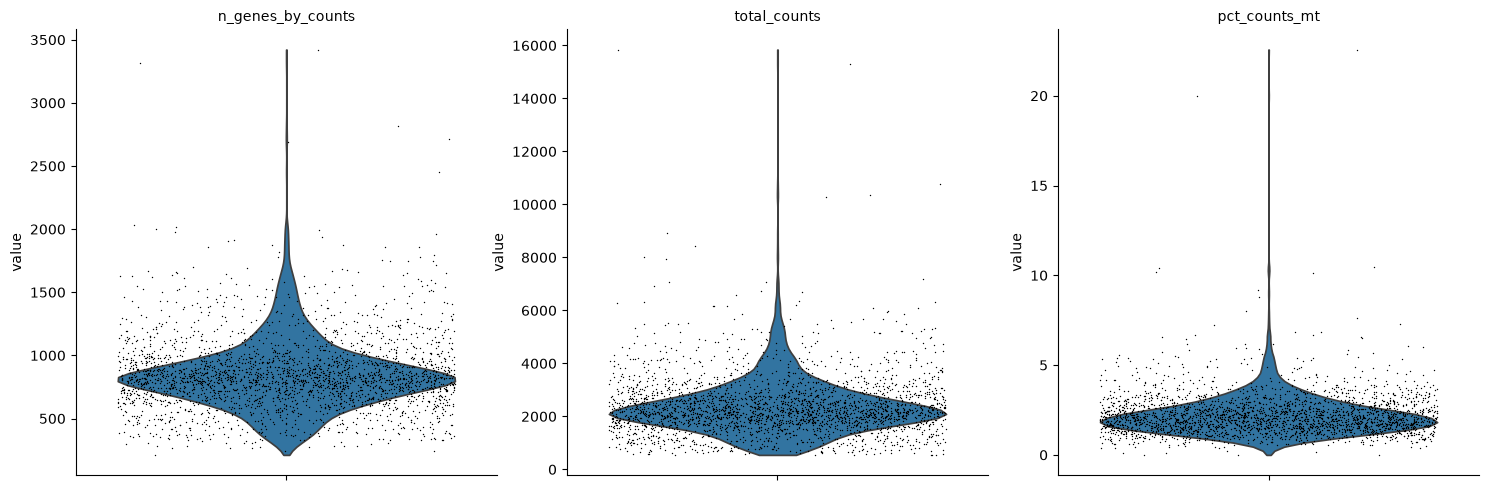

In [2]:
sc.pl.violin(
    adata,
    keys=[
        "n_genes_by_counts",
        "total_counts",
        "pct_counts_mt",
    ],
    jitter=0.4,
    multi_panel=True,
)

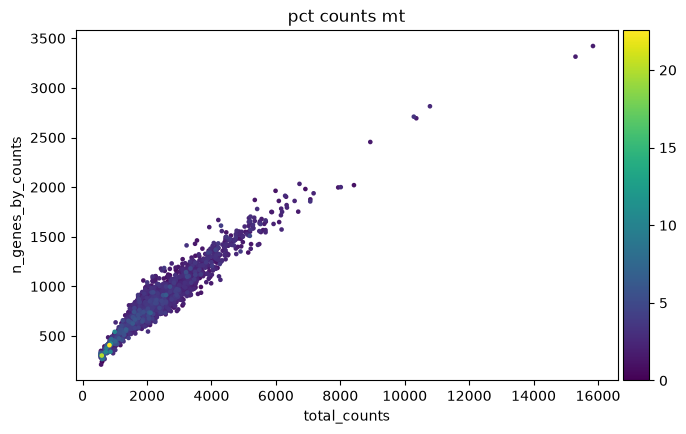

In [3]:
sc.pl.scatter(
    adata,
    x="total_counts",
    y="n_genes_by_counts",
    color="pct_counts_mt",
)

# Visualization test

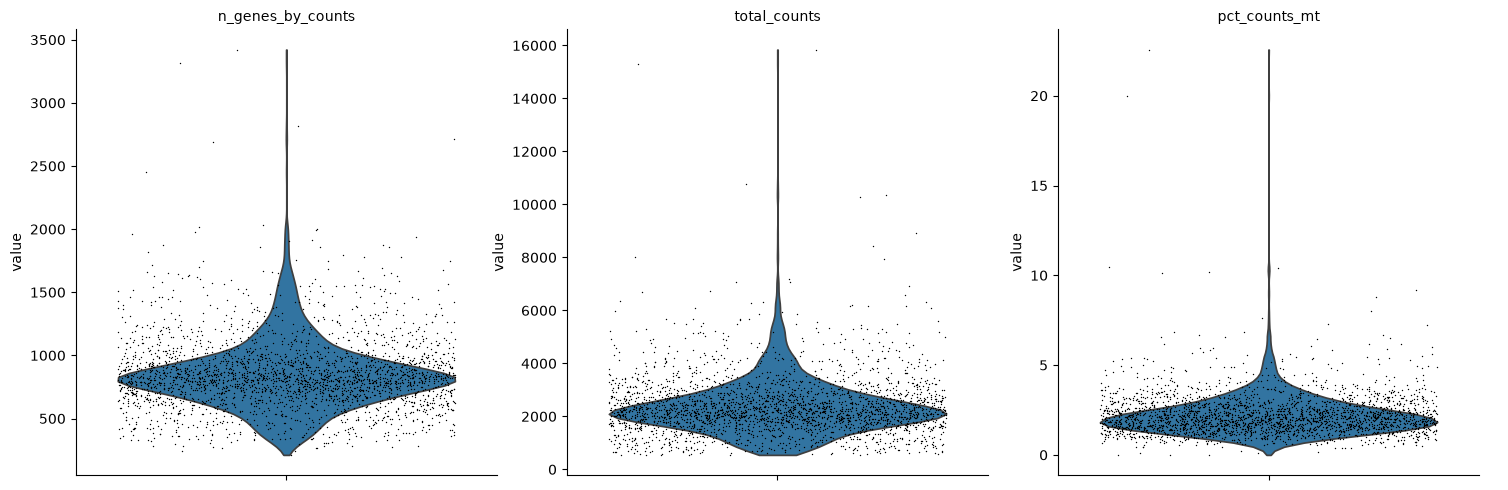

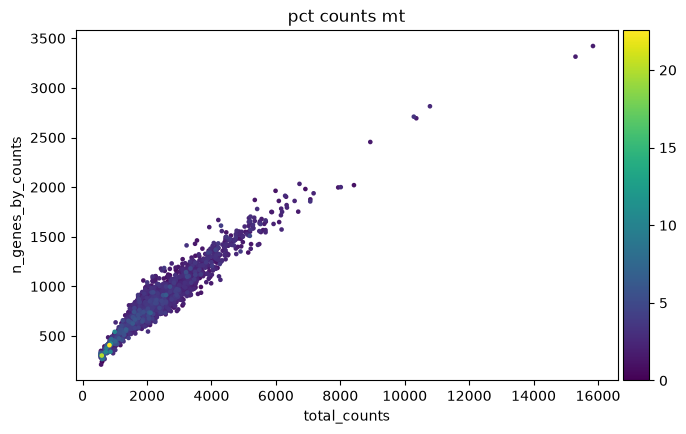

In [4]:
from sc_workflows.visualization import (
    plot_qc_violin,
    plot_qc_scatter,
)

plot_qc_violin(adata)
plot_qc_scatter(adata)

# Filtering

In [13]:
adata_filtered = filter_qc(
    adata,
    min_thresholds={
        "n_genes_by_counts": 200,
        "total_counts": 500,
    },
    max_thresholds={
        "pct_counts_mt": 7.5,
        "n_genes_by_counts": 2000,
        "total_counts":8000,
    },
    min_cells_per_gene=3,
)

In [14]:
print(f"Original cells: {adata.n_obs:,}")
print(f"Filtered cells: {adata_filtered.n_obs:,}")
print(
    f"Cells removed: "
    f"{adata.n_obs - adata_filtered.n_obs:,}"
)

Original cells: 2,700
Filtered cells: 2,681
Cells removed: 19


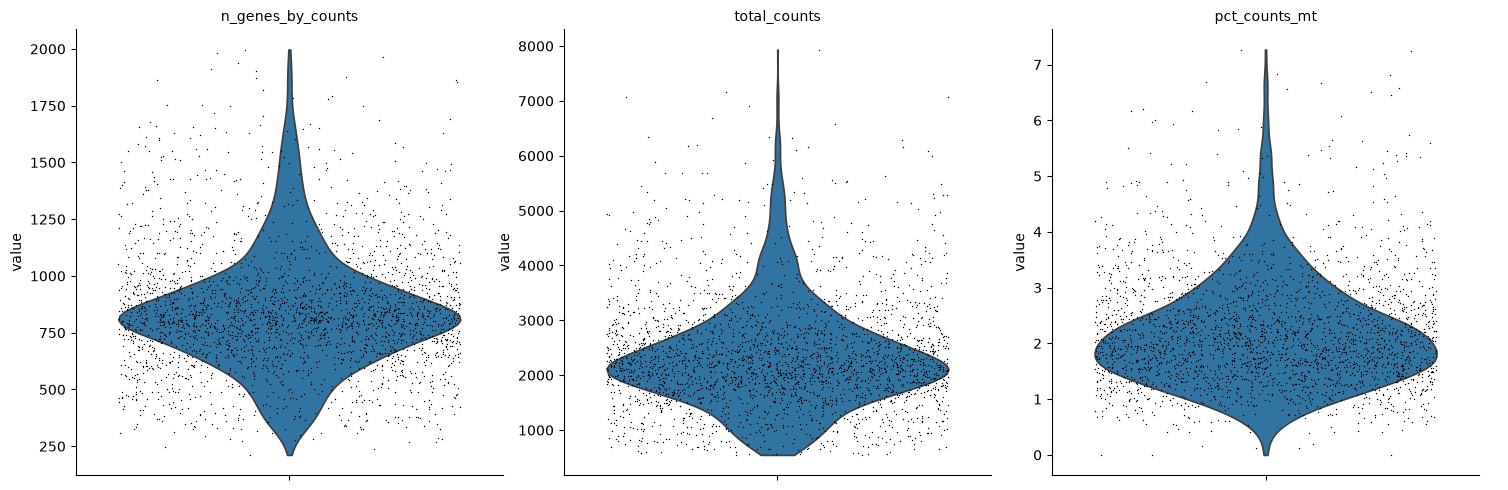

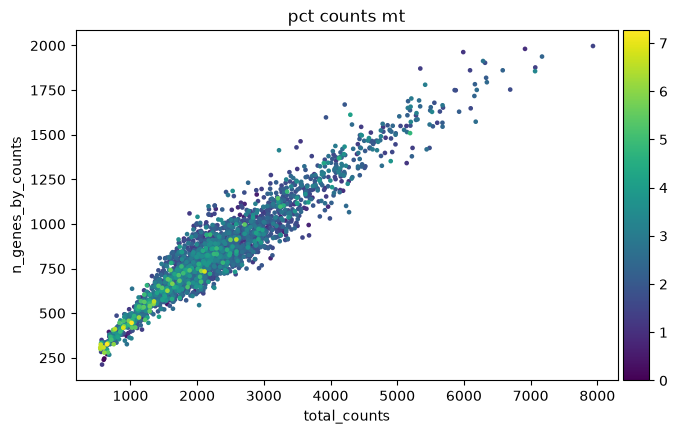

In [15]:
plot_qc_violin(adata_filtered)
plot_qc_scatter(adata_filtered)

# Saving filtered data

In [17]:
adata_filtered.write_h5ad("data/pbmc3k_filtered")